# Código para medir el tamaño y posición de los plasmas de aire y gotas de AuNP en shadowgrafía

Por Gracida Salgado Ángel David

Plasma en aire inducido por láser pulsado Nd.Yag 1064 nm, la imágen ha sido tomada con 500 ns de retraso entre el láser golpeador (1064 nm) y el láser iluminador (Nd.Yag 532 nm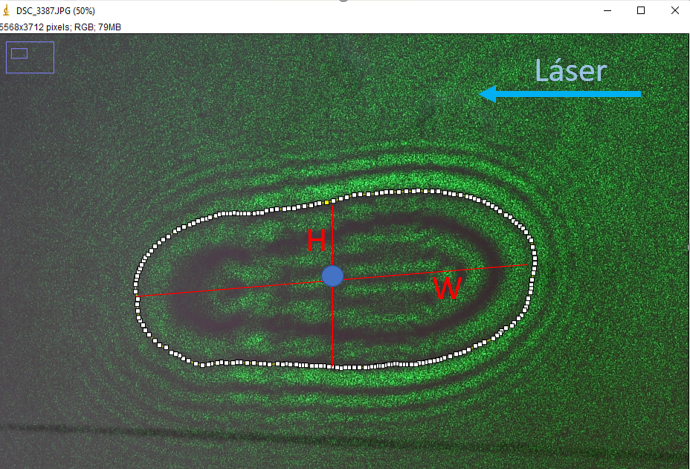)

Plasma generado en una gota de AuNP (en levitación acústica) por un láser de Nd.Yag 1064 nm, las franjas circulares indican difracción de la luz del láser iluminador y la propagación de una onda de choque producto del plasma.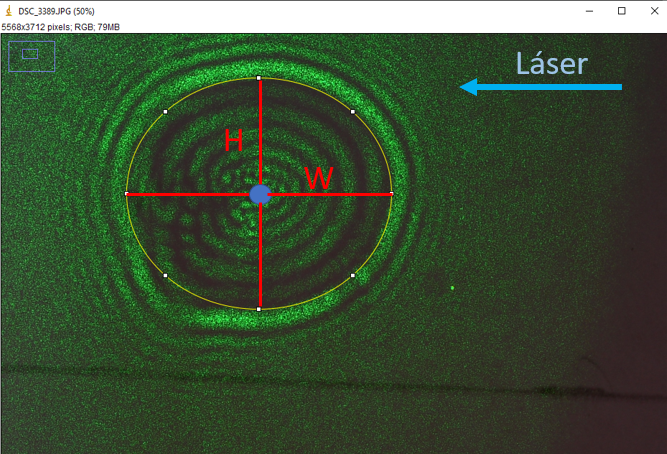

Los bordes remarcados indican la expansión de los plasmas y su onda de choque, por lo que el interés del proyecto es buscar un modelo de red neuronal que permita medir las dimensiones de estos plasmas en expansión con una exactitud mejor que la que se realiza a mano actualmente.

In [ ]:
Los bordes remarcadas de los

# Arquitectura de la red neuronal U-Net, escogida dadas sus aplicaciones en la medición de tamaños de tumores cancerígenos en imagenología médica.

In [1]:
import numpy as np
import torch, torch.nn as nn

def bloque(i, o): #bloque básico de convoluciones
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class UNet(nn.Module): #creamos la clase UNet para ejecutar el algoritmo en forma de U
    def __init__(self, in_ch=1, n_clases=1, f=(32, 64, 128, 256)):
        super().__init__()
        self.enc = nn.ModuleList()
        c = in_ch
        for k in f:
            self.enc.append(bloque(c, k)); c = k
        self.pool = nn.MaxPool2d(2)
        self.fondo = bloque(f[-1], f[-1] * 2)
        self.up = nn.ModuleList()
        self.dec = nn.ModuleList()
        c = f[-1] * 2
        for k in reversed(f):
            self.up.append(nn.ConvTranspose2d(c, k, 2, stride=2))
            self.dec.append(bloque(k * 2, k)); c = k
        self.out = nn.Conv2d(f[0], n_clases, 1)

    def forward(self, x):
        skips = []
        for e in self.enc:
            x = e(x); skips.append(x); x = self.pool(x)
        x = self.fondo(x)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):
            x = up(x)
            x = dec(torch.cat([s, x], dim=1))
        return self.out(x)  # logits

#modelo U-net para entrenarlo
modelo = UNet(in_ch=1, n_clases=1)
perdida = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(modelo.parameters(), lr=1e-3)

# Ciclo de entrenamiento
'''for imgs, masks in loader:          # imgs: (B,1,H,W), masks: (B,1,H,W) en 0/1
    opt.zero_grad()
    loss = perdida(modelo(imgs), masks)
    loss.backward()
    opt.step()'''

'for imgs, masks in loader:          # imgs: (B,1,H,W), masks: (B,1,H,W) en 0/1\n    opt.zero_grad()\n    loss = perdida(modelo(imgs), masks)\n    loss.backward()\n    opt.step()'

El estado actual del proyecto se encamina a realizar las máscaras alrededor de 50 imágenes de referencia para las imágenes de entrenamiento.